# F1.4 — Figuras de preprocesamiento (adenda)

Figuras de apoyo de la tarea F1.4 (`docs/decisiones_preprocesamiento.md`, `docs/bitacora/F1.4.md`). **No cambian resultados ni decisiones.**

Reglas que sigue este notebook:

- Las transformaciones se importan de `src/training/data.py` (`get_transforms`) y la configuración por técnica se lee de `configs/preprocesamiento.json`. No se reimplementa ninguna transformación.
- Las rutas se resuelven con `src/paths.py` y `meta/sample_index.csv`. Solo se usan imágenes de `train` y no se lee `y_true`.
- **Toda cifra que aparece en las gráficas se lee de `results/f14_preprocesamiento/*.csv`.** El notebook solo calcula lo necesario para *dibujar*: espectros radiales de ejemplos ilustrativos y la ubicación de la ventana ampliada. Nada de eso es una cifra del reporte.
- Las imágenes uint8 se muestran en escala de grises (`cmap='gray', vmin=0, vmax=255`). Tras normalizar, cada canal se muestra por separado con su barra de color, nunca como RGB.
- Estilo común: `src/viz/style.py`. Exportación a PNG a 300 dpi en `results/f14_preprocesamiento/figures/`.

In [1]:
import copy
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Rectangle
from PIL import Image
from torchvision import transforms

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():          # nbconvert ejecuta desde notebooks/
    REPO = REPO.parent
sys.path[:0] = [str(REPO / 'src'), str(REPO / 'src' / 'training')]

import paths
from data import get_transforms
from umap_io import load_umap_arrays, sha256
from viz import style

style.apply()
RES = REPO / 'results' / 'f14_preprocesamiento'
FIG = RES / 'figures'
TECHS = ['perlin', 'gray_scott', 'lorenz']
CFG = json.loads((REPO / 'configs' / 'preprocesamiento.json').read_text(encoding='utf-8'))
for t in TECHS:
    # data.py solo implementa resize/nativo; el JSON vigente usa resize en las tres
    assert CFG[t]['resize_mode'] in ('resize', 'native'), CFG[t]
{t: CFG[t] for t in TECHS}

{'perlin': {'size': 224,
  'resize_mode': 'resize',
  'interpolation': 'bilinear',
  'antialias': True,
  'hflip': False,
  'vit': 'same',
  'variant': 'px224-noflip'},
 'gray_scott': {'size': 224,
  'resize_mode': 'resize',
  'interpolation': 'bilinear',
  'antialias': True,
  'hflip': True,
  'vit': 'same',
  'variant': 'px224-flip'},
 'lorenz': {'size': 224,
  'resize_mode': 'resize',
  'interpolation': 'bilinear',
  'antialias': True,
  'hflip': False,
  'vit': 'same',
  'variant': 'px224-noflip'}}

## Insumos

`u` de train desde `umap_params.pkl` (SHA-256 verificado contra `meta/data_manifest.csv`). Del índice maestro se leen solo `sample_id`, `split`, `idx` e `img_*`, sin `y_true`.

In [2]:
manifest = pd.read_csv(paths.DATA_MANIFEST)
umap_path = paths.umap_params_path()
assert sha256(umap_path) == manifest.loc[manifest.logical_name == 'UMAP_PARAMS', 'sha256'].item()
U = load_umap_arrays(umap_path)['train']['params'].astype(np.float64)

cols = ['sample_id', 'split', 'idx'] + [f'img_{t}' for t in TECHS]
INDEX = pd.read_csv(paths.SAMPLE_INDEX, usecols=cols)
INDEX = INDEX[INDEX.split == 'train'].sort_values('idx').reset_index(drop=True)
assert len(INDEX) == len(U) == 908 and (INDEX.idx.values == np.arange(908)).all()

def load(tech, i):
    name = INDEX.loc[i, f'img_{tech}']
    assert '_train_' in name
    img = Image.open(paths.images_dir(tech) / name)
    img.load()
    assert img.mode == 'L' and img.size == (256, 256)
    return img

r2 = pd.read_csv(RES / 'r2_por_componente.csv')
flip = pd.read_csv(RES / 'sensibilidad_volteo.csv')
spec = pd.read_csv(RES / 'espectro.csv')
orient = pd.read_csv(RES / 'orientacion.csv')
print(U.shape, len(INDEX))

(908, 5) 908


## Regla de selección de ejemplos

Para cada componente $u_j$ (j = 0…4) y cada percentil q ∈ {5, 50, 95}, el ejemplo $S(j, q)$ es **la muestra de train cuyo $u_j$ está más cerca del percentil q de $u_j$ en las 908 muestras de train** (`argmin |u_j − P_q(u_j)|`; en caso de empate, el menor `idx`). Como $\mathbf{u}$ es propio de la muestra y las tres técnicas renderizan las mismas muestras, $S(j, q)$ no depende de la técnica. La regla no usa la etiqueta.

Ejemplos usados en cada figura:

| Figura | Ejemplos |
|---|---|
| 1. Pipeline | $S(0, 50)$ en las tres técnicas |
| 2. Detalle 256 vs. 224 | Perlin: $S(j^\*, 95)$; Lorenz: $S(1, 50)$ |
| 3. Espectro radial (Perlin) | $S(j^\*, 5)$ y $S(j^\*, 95)$ |
| 4. Volteo en Lorenz | $S(1, 5)$ y $S(1, 95)$ |

$j^\*$ es el componente con mayor ρ positivo entre la fracción de energía por encima de 112 ciclos por imagen y $u_j$ en Perlin, leído de `espectro.csv` (P3). Así, los ejemplos de u bajo y alto son los de menor y mayor contenido de alta frecuencia esperado.

La ventana ampliada de la figura 2 se elige así: la ventana de 64 × 64 px, sobre una rejilla de paso 16 px de la imagen de 256 px, con mayor desviación estándar de intensidad. Su equivalente en 224 px es la misma región escalada por 224/256 (56 × 56 px).

In [3]:
PCTS = (5, 50, 95)

def nearest_to_percentile(j, q):
    return int(np.argmin(np.abs(U[:, j] - np.percentile(U[:, j], q))))   # argmin: empate -> menor idx

S = {(j, q): nearest_to_percentile(j, q) for j in range(5) for q in PCTS}
p3_perlin = spec[spec.technique == 'perlin'].set_index('component')['rho']
J_STAR = int(p3_perlin.idxmax()[1])

sel = pd.DataFrame([{'componente': f'u{j}', 'percentil': q, 'idx': i, 'sample_id': INDEX.loc[i, 'sample_id'],
                     f'u_j': round(U[i, j], 4)} for (j, q), i in S.items()])
print(f'j* = u{J_STAR} (rho P3 Perlin = {p3_perlin.max():.4f}, espectro.csv)')
sel.pivot(index='componente', columns='percentil', values='sample_id')

j* = u3 (rho P3 Perlin = 0.6325, espectro.csv)


percentil,5,50,95
componente,,,
u0,train_0223,train_0043,train_0690
u1,train_0343,train_0268,train_0462
u2,train_0848,train_0022,train_0062
u3,train_0869,train_0095,train_0720
u4,train_0086,train_0153,train_0084


## Figura 1. Pipeline paso a paso

Una fila por técnica, con el ejemplo $S(0, 50)$. Los pasos son los objetos de la cadena de `get_transforms(train=True, img_size=size, hflip=…)` de `data.py`, con `size` y `hflip` leídos de `configs/preprocesamiento.json`. En `data.py` el orden real es `Grayscale(3) → Resize → volteo → ToTensor → Normalize`. Aquí se muestra *redimensionar → replicar a 3 canales*; como los tres canales son idénticos, el resultado es el mismo, y la celda lo verifica. Los histogramas usan escala logarítmica porque el fondo negro concentra la mayoría de los píxeles: el tensor final coincide exactamente con `get_transforms(False, size)(img)`.

El volteo se muestra siempre, para ilustrarlo. El título indica si el JSON lo permite para esa técnica. Cuando no está permitido, `get_transforms` no lo incluye y se ilustra con `transforms.RandomHorizontalFlip(p=1.0)` de torchvision.

C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f14_preprocesamiento\figures\fig1_pipeline.png


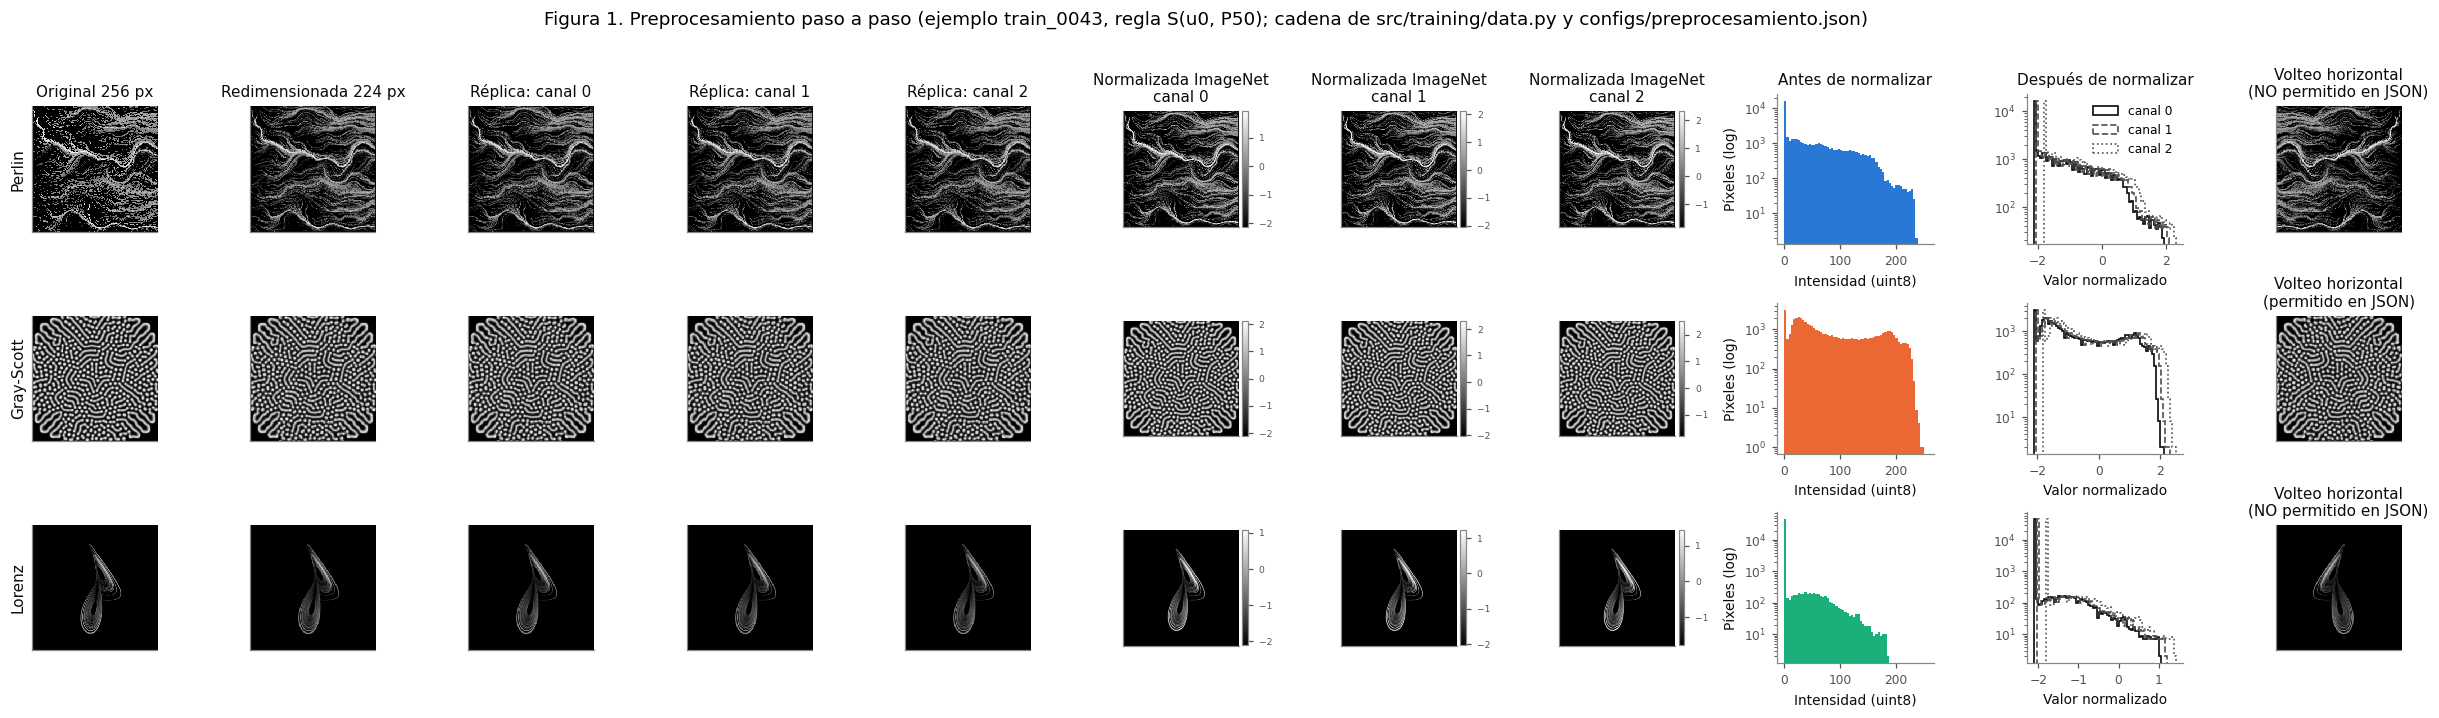

In [4]:
def pipeline_steps(tech):
    cfg = CFG[tech]
    tf = get_transforms(True, cfg['size'], hflip=cfg['hflip'])
    by_type = {type(s): s for s in tf.transforms}
    gray3 = by_type[transforms.Grayscale]
    resize = by_type.get(transforms.Resize)            # None si size == 256 (nativo)
    to_tensor, normalize = by_type[transforms.ToTensor], by_type[transforms.Normalize]
    flip_step = by_type.get(transforms.RandomHorizontalFlip)
    if flip_step is not None:
        flip_step = copy.copy(flip_step)
        flip_step.p = 1.0                              # mostrar siempre el volteo
    else:
        flip_step = transforms.RandomHorizontalFlip(p=1.0)
    return gray3, resize, to_tensor, normalize, flip_step


def run_pipeline(tech, img):
    gray3, resize, to_tensor, normalize, flip_step = pipeline_steps(tech)
    resized = resize(img) if resize is not None else img
    rgb = gray3(resized)
    x = normalize(to_tensor(rgb))
    ref = get_transforms(False, CFG[tech]['size'])(img)
    assert torch.equal(x, ref), f'{tech}: el orden mostrado no reproduce data.py'
    return {'orig': np.asarray(img), 'resized': np.asarray(resized), 'rgb': np.asarray(rgb),
            'norm': x.numpy(), 'flip': np.asarray(flip_step(rgb))[..., 0]}


i0 = S[(0, 50)]
cols = ['Original 256 px', f'Redimensionada', 'Canal 0', 'Canal 1', 'Canal 2',
        'Normalizada, canal 0', 'Normalizada, canal 1', 'Normalizada, canal 2',
        'Histograma antes', 'Histograma después', 'Volteo']
fig, axes = plt.subplots(3, len(cols), figsize=(22, 6.4),
                         gridspec_kw={'width_ratios': [1] * 8 + [1.25, 1.25, 1]})
for r, tech in enumerate(TECHS):
    st = run_pipeline(tech, load(tech, i0))
    size = CFG[tech]['size']
    ax = axes[r]
    style.gray(ax[0], st['orig'], cols[0] if r == 0 else None)
    style.gray(ax[1], st['resized'], f'Redimensionada {size} px' if r == 0 else None)
    for c in range(3):
        style.gray(ax[2 + c], st['rgb'][..., c], f'Réplica: canal {c}' if r == 0 else None)
    for c in range(3):
        a = ax[5 + c]
        im = a.imshow(st['norm'][c], cmap='gray')
        a.set_xticks([]); a.set_yticks([])
        if r == 0:
            a.set_title(f'Normalizada ImageNet\ncanal {c}')
        cb = fig.colorbar(im, ax=a, fraction=0.046, pad=0.03)
        cb.ax.tick_params(labelsize=6)
    a = ax[8]
    a.hist(st['resized'].ravel(), bins=64, range=(0, 255), color=style.TECH_COLOR[tech], linewidth=0)
    a.set_yscale('log'); a.set_xlabel('Intensidad (uint8)'); a.set_ylabel('Píxeles (log)')
    if r == 0:
        a.set_title('Antes de normalizar')
    a = ax[9]
    for c, ls in zip(range(3), ('-', '--', ':')):
        a.hist(st['norm'][c].ravel(), bins=64, histtype='step', linestyle=ls, linewidth=1.1,
               color=style.INK if c == 0 else style.INK_SECONDARY, label=f'canal {c}')
    a.set_yscale('log'); a.set_xlabel('Valor normalizado')
    if r == 0:
        a.set_title('Después de normalizar'); a.legend(loc='upper right')
    permitido = 'permitido' if CFG[tech]['hflip'] else 'NO permitido'
    style.gray(ax[10], st['flip'], f'Volteo horizontal\n({permitido} en JSON)')
    ax[0].set_ylabel(style.TECH_LABEL[tech], fontsize=style.FONT_SIZES['title'], color=style.INK)
fig.suptitle(f'Figura 1. Preprocesamiento paso a paso (ejemplo {INDEX.loc[i0, "sample_id"]}, '
             f'regla S(u0, P50); cadena de src/training/data.py y configs/preprocesamiento.json)', y=1.01)
fig.tight_layout()
print(style.save(fig, FIG / 'fig1_pipeline'))
plt.show()

## Figura 2. Detalle ampliado: 256 px frente a 224 px

Regiones de alta frecuencia en Perlin ($S(j^\*, 95)$) y de trazos finos en Lorenz ($S(1, 50)$), en apoyo de H5. La imagen de 224 px es la salida del paso `Resize` de `data.py`. Las ampliaciones usan interpolación *nearest* para mostrar los píxeles tal como son.

C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f14_preprocesamiento\figures\fig2_detalle_256_vs_224.png


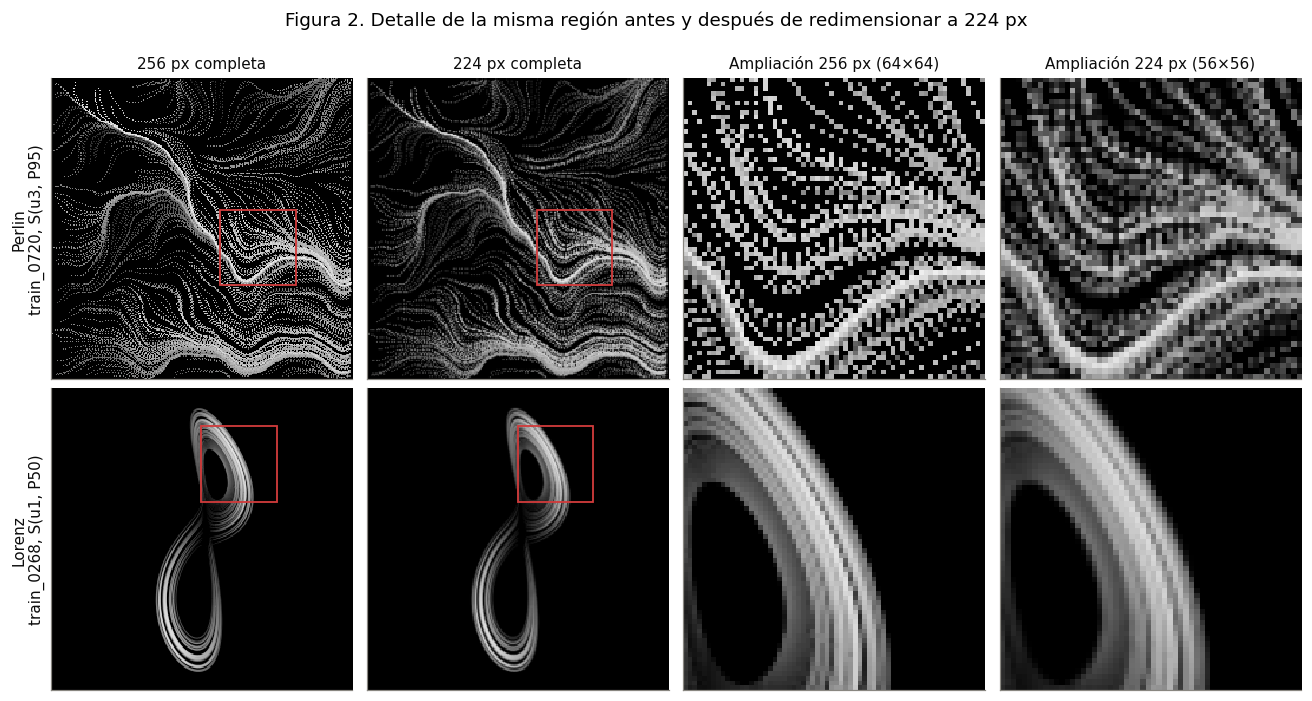

In [5]:
def max_std_window(a, w=64, step=16):
    best, pos = -1.0, (0, 0)
    for r0 in range(0, a.shape[0] - w + 1, step):
        for c0 in range(0, a.shape[1] - w + 1, step):
            s = a[r0:r0 + w, c0:c0 + w].std()
            if s > best:
                best, pos = s, (r0, c0)
    return pos


cases = [('perlin', S[(J_STAR, 95)], f'S(u{J_STAR}, P95)'), ('lorenz', S[(1, 50)], 'S(u1, P50)')]
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for r, (tech, i, rule) in enumerate(cases):
    img = load(tech, i)
    resize = pipeline_steps(tech)[1]
    a256, a224 = np.asarray(img), np.asarray(resize(img))
    W = 64
    r0, c0 = max_std_window(a256.astype(float), W)
    k = a224.shape[0] / 256
    r1, c1, W1 = round(r0 * k), round(c0 * k), round(W * k)
    for ax, a, (rr, cc, ww), title in ((axes[r, 0], a256, (r0, c0, W), '256 px completa'),
                                       (axes[r, 1], a224, (r1, c1, W1), f'{a224.shape[0]} px completa')):
        style.gray(ax, a, title if r == 0 else None)
        ax.add_patch(Rectangle((cc - .5, rr - .5), ww, ww, fill=False, edgecolor=style.THRESHOLD_COLOR, lw=1.2))
    style.gray(axes[r, 2], a256[r0:r0 + W, c0:c0 + W], f'Ampliación 256 px ({W}×{W})' if r == 0 else None)
    style.gray(axes[r, 3], a224[r1:r1 + W1, c1:c1 + W1],
               f'Ampliación {a224.shape[0]} px ({W1}×{W1})' if r == 0 else None)
    axes[r, 0].set_ylabel(f'{style.TECH_LABEL[tech]}\n{INDEX.loc[i, "sample_id"]}, {rule}',
                          fontsize=style.FONT_SIZES['title'], color=style.INK)
fig.suptitle('Figura 2. Detalle de la misma región antes y después de redimensionar a 224 px', y=1.0)
fig.tight_layout()
print(style.save(fig, FIG / 'fig2_detalle_256_vs_224'))
plt.show()

## Figura 3. Espectro de potencia radial en Perlin (P3)

Promedio radial de |FFT2|² (sin la media) de dos ejemplos de Perlin con $u_{j^\*}$ bajo ($S(j^\*, 5)$) y alto ($S(j^\*, 95)$). La línea vertical marca 112 ciclos por imagen, la frecuencia de Nyquist a 224 px. P3 mide la energía con max(|f_x|, |f_y|) > 112, una región cuadrada; el eje radial de esta figura es ilustrativo. Las curvas son descriptivas: la cifra de P3 que se reporta es la de `espectro.csv` (ρ en la leyenda).

C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f14_preprocesamiento\figures\fig3_espectro_perlin.png


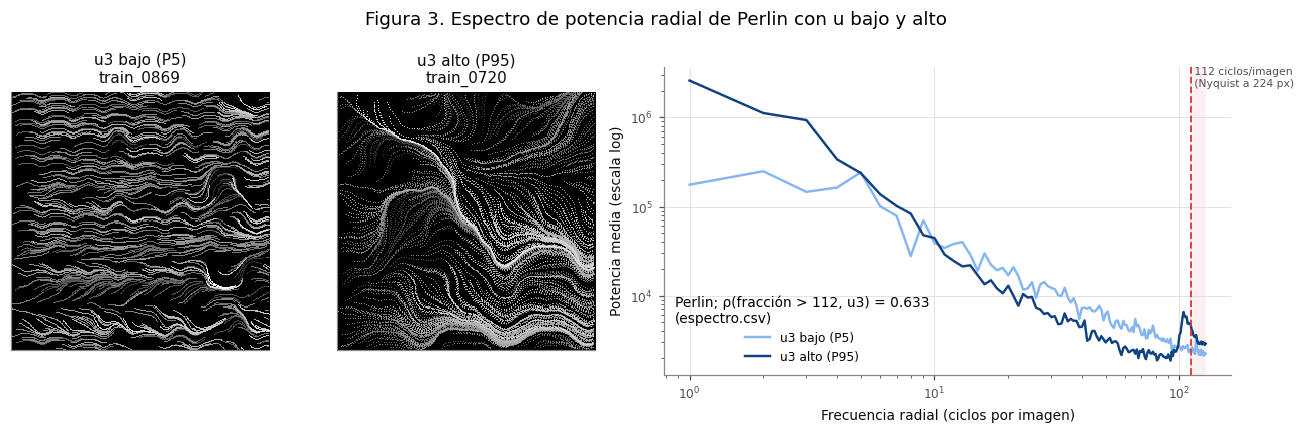

In [6]:
def radial_power(a):
    a = a.astype(np.float64) / 255.0
    P = np.abs(np.fft.fftshift(np.fft.fft2(a - a.mean()))) ** 2
    yy, xx = np.indices(P.shape)
    rad = np.hypot(xx - a.shape[1] // 2, yy - a.shape[0] // 2).round().astype(int)
    prof = np.bincount(rad.ravel(), P.ravel()) / np.bincount(rad.ravel())
    return np.arange(1, 129), prof[1:129]


lo, hi = S[(J_STAR, 5)], S[(J_STAR, 95)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw={'width_ratios': [1, 1, 2.2]})
shades = {lo: '#86b6ef', hi: '#104281'}    # secuencial de un solo tono: claro = u bajo, oscuro = u alto
for ax, i, lab in ((axes[0], lo, 'bajo (P5)'), (axes[1], hi, 'alto (P95)')):
    style.gray(ax, np.asarray(load('perlin', i)), f'u{J_STAR} {lab}\n{INDEX.loc[i, "sample_id"]}')
ax = axes[2]
for i, lab in ((lo, 'bajo (P5)'), (hi, 'alto (P95)')):
    f, p = radial_power(np.asarray(load('perlin', i)))
    ax.loglog(f, p, color=shades[i], label=f'u{J_STAR} {lab}')
ax.axvline(112, color=style.THRESHOLD_COLOR, ls='--', lw=1.2)
ax.axvspan(112, 128, color=style.THRESHOLD_COLOR, alpha=0.08, lw=0)
ax.text(112, ax.get_ylim()[1], ' 112 ciclos/imagen\n (Nyquist a 224 px)', va='top', ha='left',
        color=style.INK_SECONDARY, fontsize=style.FONT_SIZES['annot'])
ax.set_xlabel('Frecuencia radial (ciclos por imagen)')
ax.set_ylabel('Potencia media (escala log)')
ax.grid(True, which='major')
rho = p3_perlin[f'u{J_STAR}']
ax.legend(title=f'Perlin; ρ(fracción > 112, u{J_STAR}) = {rho:.3f}\n(espectro.csv)', loc='lower left')
fig.suptitle('Figura 3. Espectro de potencia radial de Perlin con u bajo y alto', y=1.02)
fig.tight_layout()
print(style.save(fig, FIG / 'fig3_espectro_perlin'))
plt.show()

## Figura 4. Lorenz: original frente a volteada (P2, H2)

Ejemplos con $u_1$ extremo ($S(1, 5)$ y $S(1, 95)$), sin voltear y volteados (`RandomHorizontalFlip(p=1.0)`; el JSON no permite el volteo en Lorenz). A la derecha, el R² de $u_1$ sin y con volteo de la partición retenida, leído de `sensibilidad_volteo.csv`. V1 es la variante decidida.

C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f14_preprocesamiento\figures\fig4_volteo_lorenz.png


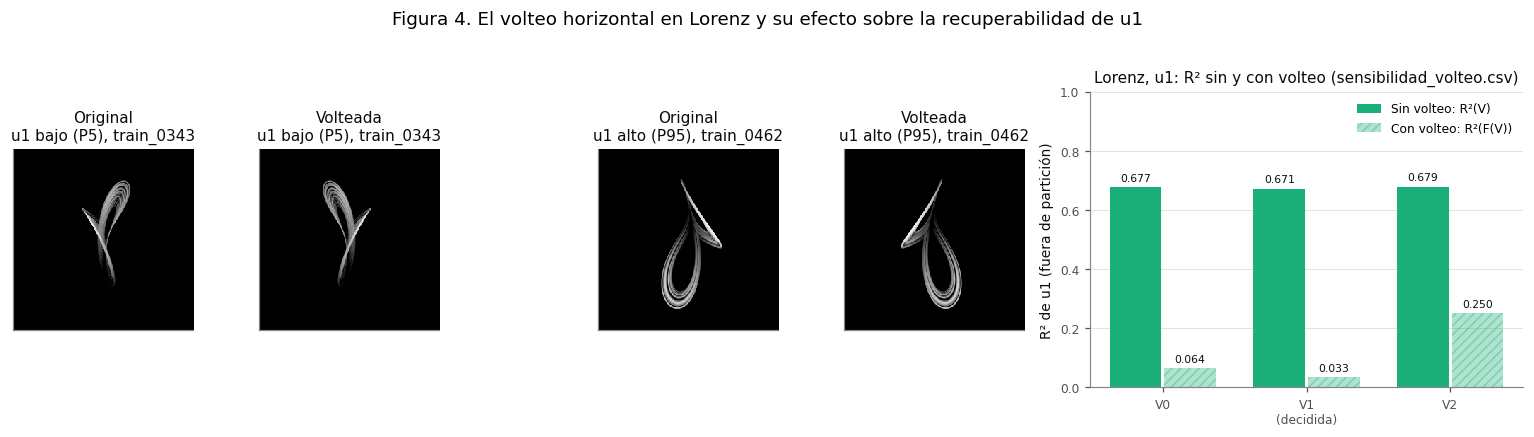

In [7]:
flipper = pipeline_steps('lorenz')[4]
fig = plt.figure(figsize=(14, 3.8))
gs = fig.add_gridspec(1, 6, width_ratios=[1, 1, 0.15, 1, 1, 2.4])
for k, (i, lab) in enumerate(((S[(1, 5)], 'u1 bajo (P5)'), (S[(1, 95)], 'u1 alto (P95)'))):
    img = load('lorenz', i)
    for m, (a, t) in enumerate(((np.asarray(img), 'Original'), (np.asarray(flipper(img)), 'Volteada'))):
        ax = fig.add_subplot(gs[0, 3 * k + m])
        style.gray(ax, a, f'{t}\n{lab}, {INDEX.loc[i, "sample_id"]}')

ax = fig.add_subplot(gs[0, 5])
d = flip[(flip.technique == 'lorenz') & (flip.component == 'u1')].set_index('variant').loc[['V0', 'V1', 'V2']]
x = np.arange(len(d))
w = 0.36
b1 = ax.bar(x - w / 2 - 0.01, d['R2_V'], w, color=style.TECH_COLOR['lorenz'], label='Sin volteo: R²(V)')
b2 = ax.bar(x + w / 2 + 0.01, d['R2_FV'], w, color=style.TECH_COLOR['lorenz'], alpha=0.35,
            hatch='////', edgecolor=style.TECH_COLOR['lorenz'], linewidth=0, label='Con volteo: R²(F(V))')
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015, f'{bar.get_height():.3f}',
                ha='center', va='bottom', fontsize=style.FONT_SIZES['annot'], color=style.INK)
ax.set_xticks(x, [f'{v}\n(decidida)' if v == 'V1' else v for v in d.index])
ax.set_ylim(0, 1)
ax.set_ylabel('R² de u1 (fuera de partición)')
ax.set_title('Lorenz, u1: R² sin y con volteo (sensibilidad_volteo.csv)')
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.legend(loc='upper right')
fig.suptitle('Figura 4. El volteo horizontal en Lorenz y su efecto sobre la recuperabilidad de u1', y=1.03)
fig.tight_layout()
print(style.save(fig, FIG / 'fig4_volteo_lorenz'))
plt.show()

## Figura 5. ΔR² por componente y técnica (P1 y P2)

Estimador puntual e IC 95 % por *bootstrap* pareado, leídos de `r2_por_componente.csv` (P1: V1 y V2 frente a V0) y de `sensibilidad_volteo.csv` (P2: volteo sobre V1, la variante a la que se aplica la regla 3). La línea roja discontinua es el umbral de 0.02. El panel de P2 usa escala *symlog* (lineal en ±0.05) porque Lorenz supera el umbral por más de un orden de magnitud.

C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f14_preprocesamiento\figures\fig5_delta_r2.png


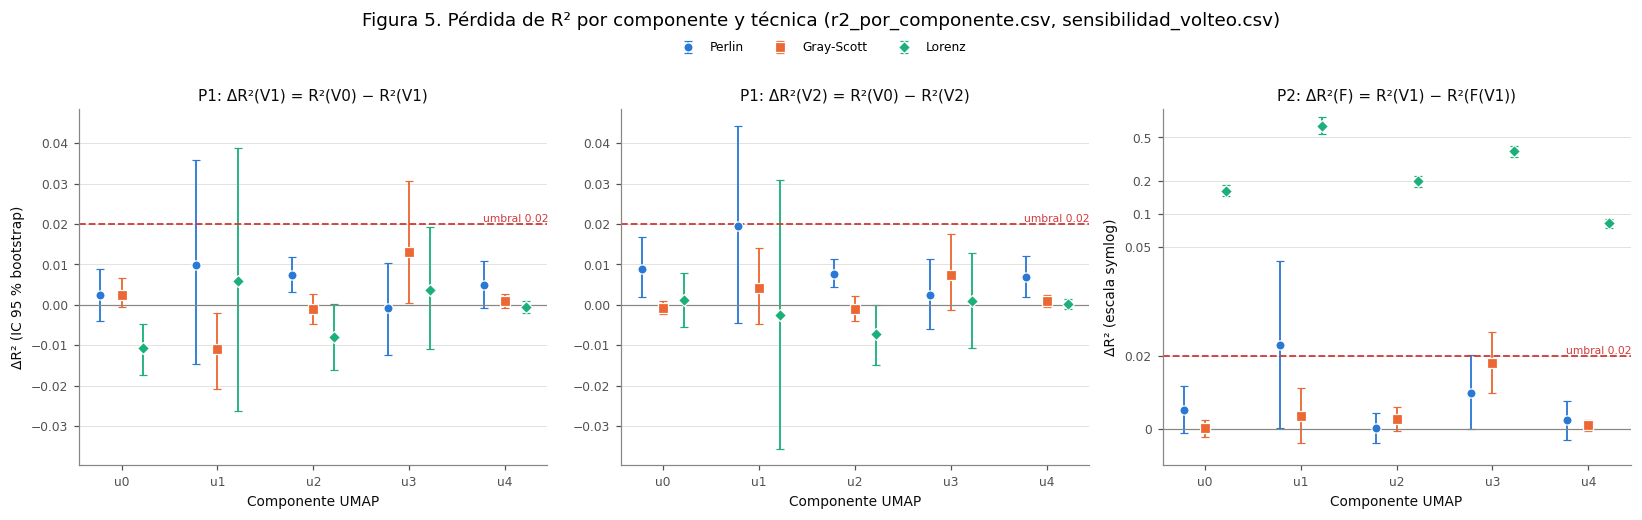

In [8]:
comps = [f'u{j}' for j in range(5)]
panels = [
    ('P1: ΔR²(V1) = R²(V0) − R²(V1)', r2[r2.variant == 'V1'], 'dR2', False),
    ('P1: ΔR²(V2) = R²(V0) − R²(V2)', r2[r2.variant == 'V2'], 'dR2', False),
    ('P2: ΔR²(F) = R²(V1) − R²(F(V1))', flip[flip.variant == 'V1'], 'dR2_F', True),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
axes[1].sharey(axes[0])   # P1: misma escala para V1 y V2
offs = {'perlin': -0.22, 'gray_scott': 0.0, 'lorenz': 0.22}
markers = {'perlin': 'o', 'gray_scott': 's', 'lorenz': 'D'}
for ax, (title, df, col, symlog) in zip(axes, panels):
    for tech in TECHS:
        d = df[df.technique == tech].set_index('component').loc[comps]
        xs = np.arange(5) + offs[tech]
        yerr = np.vstack([d[col] - d['ic_lo'], d['ic_hi'] - d[col]])
        ax.errorbar(xs, d[col], yerr=yerr, fmt=markers[tech], color=style.TECH_COLOR[tech], ms=6,
                    elinewidth=1.2, capsize=2.5, label=style.TECH_LABEL[tech],
                    markeredgecolor='white', markeredgewidth=0.8)
    ax.axhline(0.02, color=style.THRESHOLD_COLOR, ls='--', lw=1.2)
    ax.axhline(0, color=style.MUTED, lw=0.8)
    if symlog:
        ax.set_yscale('symlog', linthresh=0.05, linscale=1.5)
        ticks = [0, 0.02, 0.05, 0.1, 0.2, 0.5]
        ax.set_yticks(ticks, [f'{t:g}' for t in ticks])
        ax.yaxis.set_minor_locator(plt.NullLocator())
        ax.set_ylim(-0.01, 0.9)
    ax.text(4.45, 0.02, 'umbral 0.02', color=style.THRESHOLD_COLOR, va='bottom', ha='right',
            fontsize=style.FONT_SIZES['annot'])
    ax.set_xticks(range(5), comps)
    ax.set_xlabel('Componente UMAP')
    ax.set_title(title)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
axes[0].set_ylabel('ΔR² (IC 95 % bootstrap)')
axes[2].set_ylabel('ΔR² (escala symlog)')
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle('Figura 5. Pérdida de R² por componente y técnica (r2_por_componente.csv, sensibilidad_volteo.csv)', y=1.06)
fig.tight_layout()
fig.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.02))
print(style.save(fig, FIG / 'fig5_delta_r2'))
plt.show()

## Figura 6. Correlaciones de orientación (P4)

ρ de Spearman entre cada estadístico de orientación con signo y cada $u_j$, leído de `orientacion.csv`. Los asteriscos marcan los contrastes significativos tras Holm (30 contrastes, α = 0.05; columna `significativo`).

C:\Users\DELL\Desktop\TT\TT2\ttdicevc\results\f14_preprocesamiento\figures\fig6_orientacion_p4.png


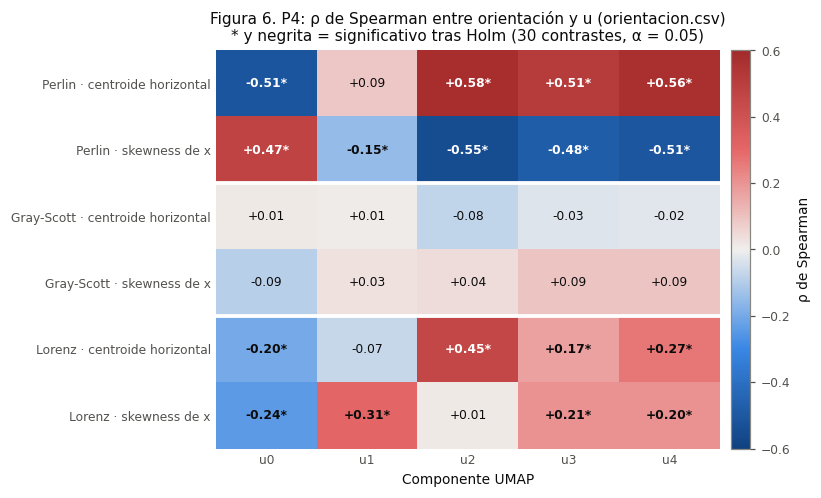

In [9]:
stat_label = {'centroide_x': 'centroide horizontal', 'skew_x': 'skewness de x'}
rows, row_labels, sig = [], [], []
for tech in TECHS:
    for stat in ('centroide_x', 'skew_x'):
        d = orient[(orient.technique == tech) & (orient.statistic == stat)].set_index('component').loc[comps]
        rows.append(d['rho'].values)
        sig.append(d['significativo'].values)
        row_labels.append(f'{style.TECH_LABEL[tech]} · {stat_label[stat]}')
M, SIG = np.array(rows), np.array(sig)
lim = np.ceil(np.abs(M).max() * 10) / 10
fig, ax = plt.subplots(figsize=(7.5, 4.6))
im = ax.imshow(M, cmap=style.DIVERGING, vmin=-lim, vmax=lim, aspect='auto')
for r in range(M.shape[0]):
    for c in range(M.shape[1]):
        txt = f'{M[r, c]:+.2f}' + ('*' if SIG[r, c] else '')
        ax.text(c, r, txt, ha='center', va='center', fontsize=style.FONT_SIZES['annot'] + 1,
                color='white' if abs(M[r, c]) > 0.6 * lim else style.INK,
                fontweight='bold' if SIG[r, c] else 'normal')
for r in (1.5, 3.5):
    ax.axhline(r, color='white', lw=2.5)
ax.set_xticks(range(5), comps)
ax.set_yticks(range(len(row_labels)), row_labels)
ax.set_xlabel('Componente UMAP')
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label('ρ de Spearman')
ax.set_title('Figura 6. P4: ρ de Spearman entre orientación y u (orientacion.csv)\n'
             '* y negrita = significativo tras Holm (30 contrastes, α = 0.05)')
fig.tight_layout()
print(style.save(fig, FIG / 'fig6_orientacion_p4'))
plt.show()

In [10]:
sorted(p.name for p in FIG.glob('*.png'))

['fig1_pipeline.png',
 'fig2_detalle_256_vs_224.png',
 'fig3_espectro_perlin.png',
 'fig4_volteo_lorenz.png',
 'fig5_delta_r2.png',
 'fig6_orientacion_p4.png']